# Практическое занятие №1-2
**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач»

Ниже — разбор примера из методических указаний (парная линейная регрессия и градиентный спуск), затем — решение задания на данных «Гиперспектр кукурузы».

Парная линейная регрессия
Цель работы
    Познакомиться с моделью парной линейной регрессии регрессии и методом градиентного спуска.

Содержание работы
Найти оценки параметров модели парной линейной регрессии прямыми вычислениями и палучить с помощью модели прогнозы результативного прознака.
Найти оценки параметров модели парной линейной регрессии с использованием метода градиентного спуска.
Оценить качество построенной модели, сравнив на графике обучающую выборку и прогнозы.
Построить кривые обучения.

In [1]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = np.array([3, 5, 7, 6, 9])
Y = np.array([3, 7, 11, 14, 15])
display(x, Y)

array([3, 5, 7, 6, 9])

array([ 3,  7, 11, 14, 15])

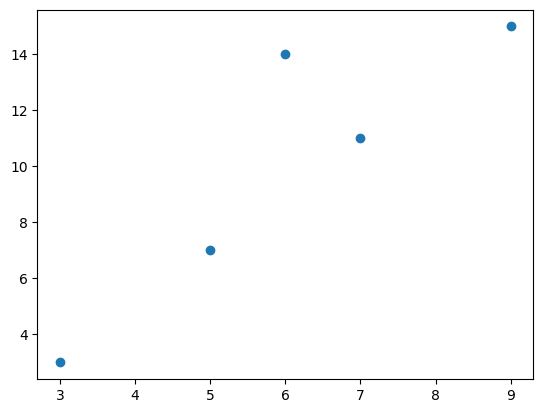

In [3]:
#Изобразим их на графике
plt.figure()
plt.scatter(x, Y)
plt.show()

In [4]:
#Вычислим оценки коэффициентов парной линейной регрессии по формулам
a1 = ((x - x.mean())*(Y - Y.mean())).mean()/((x - x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Модель линейной регрессии: Y^ = ", a0, " + ", a1, "* x")

Модель линейной регрессии: Y^ =  -2.0  +  2.0 * x


In [5]:
#Дадим серию прогнозов Y^ для x от 3 до 9 с шагом 1
x_space = np.linspace(3, 9, 7)
print(x_space)
Y_pred = a0 + a1*x_space
print(Y_pred)

[3. 4. 5. 6. 7. 8. 9.]
[ 4.  6.  8. 10. 12. 14. 16.]


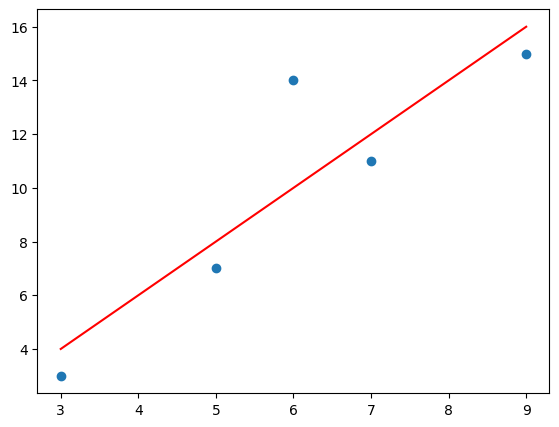

In [6]:
#Изобразим на графике исходные данные и прогнозы 
fig  = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')
#ax.scatter(x_space, Y_pred)

In [7]:
#Реализуем шаг градиентного спуска в модели парной лдинейной регрессии
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0
    def predict(self, x):
        return self.a0 + self.a1*x
    def MSE(self, x, Y):
        return ((self.predict(x)-Y)**2).mean()
    def fit(self, x, Y):
        alpha = 0.1
        dT_a0 = -2*sum((Y -self.predict(x)))
        dT_a1 = -2*sum((Y -self.predict(x))*x)
        self.a0 -= alpha*dT_a0
        self.a1 -= alpha*dT_a1

In [8]:
#Получим прогнозы до градиентного спуска с начальными значениями параметров
regr = SimpleRegression()
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print(regr.MSE(x, Y))

0
0
0
0
0
120.0


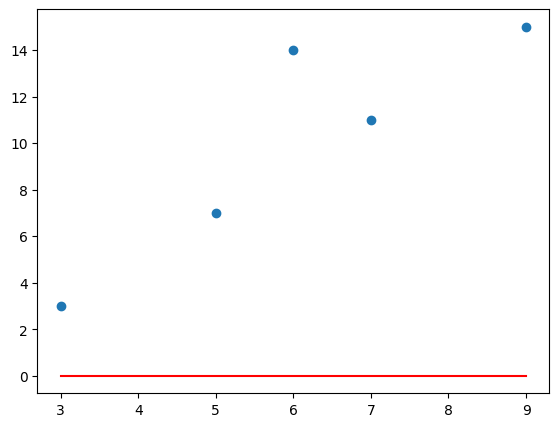

In [9]:
#Выведем прогнозы до градиентного спуска на графике
x_space = np.linspace(3, 9, 7)
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

MSE после первого шага градиентного спуска:  183892.0


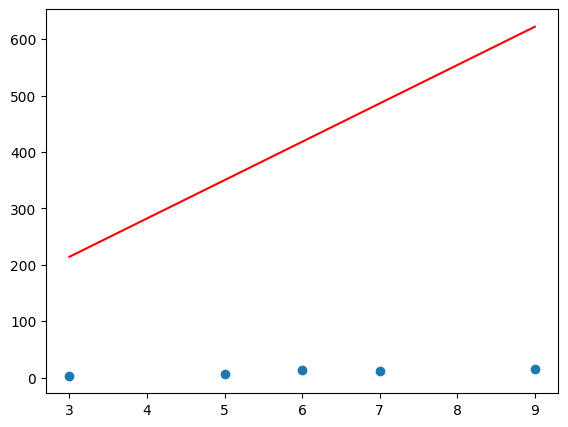

In [10]:
#Реализуем шаг градиентного спуска
regr.fit(x, Y)
print("MSE после первого шага градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

In [11]:
#Реализуем цикл градиентного спуска
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0
    def predict(self, x):
        return self.a0 + self.a1*x
    def MSE(self, x, Y):
        return ((Y - self.predict(x))**2).mean()
    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()
    def MAPE(self, x, Y):
        return abs((Y - self.predict(x))/Y).mean()
    def fit(self, x, Y, alpha = 0.001, epsylon = 0.01, max_steps = 5000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2*sum((Y -self.predict(x)))
            dT_a1 = -2*sum((Y -self.predict(x))*x)
            self.a0 -= alpha*dT_a0
            self.a1 -= alpha*dT_a1
            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)
            if new_error < epsylon:
                break
        return steps, errors

In [12]:
#Запустим цикл градиентного спуска с заданной точностью 5
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.001, epsylon = 5)

5.004697916218
8.190462542210001
11.376227168202002
9.783344855206002
14.561991794194002
MSE после градиентного спуска:  4.709918696051655


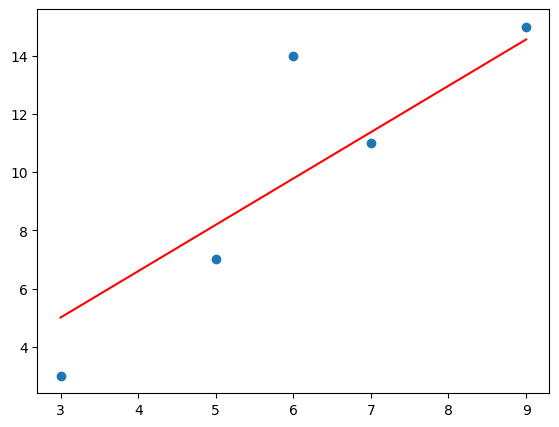

In [13]:
#Выведем график  прогнозов и вычислим MSE
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

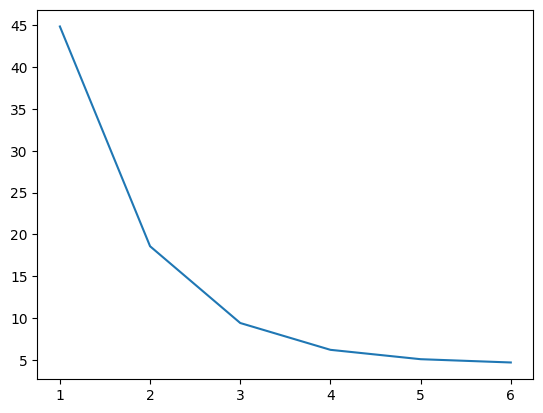

In [14]:
#Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

In [15]:
#Запустим цикл градиентного спуска с заданной точностью 0.05
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.001, epsylon = 0.05)

MSE после градиентного спуска:  4.000028517306817


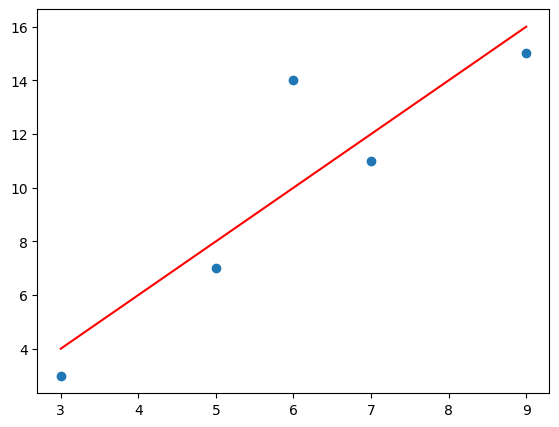

In [16]:
#Выведем график прогнозов и вычислим MSE
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

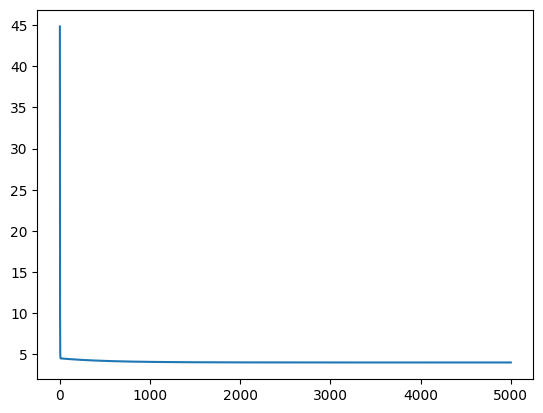

In [17]:
#Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

MSE после градиентного спуска: 

 4.1903709155046345


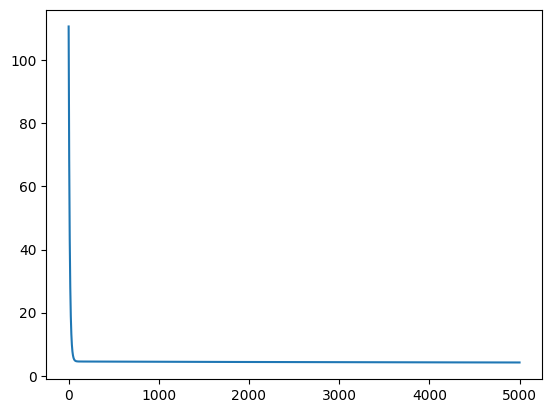

In [18]:
#Запустим цикл градиентного спуска с разными значениями скорости обучения alpha=0.0001, 0.01, 0.1, 1, 10, ..., 
#с различной допукстимой точностью epsylon = 0.001, 0.5, 5, с различным максимальным количеством шагов max_steps
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.0001, epsylon = 0.01, max_steps = 5000)
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
plt.figure()
plt.plot(steps, errors)

Загрузите файл Гиперспектр кукурузы.csv (с помощью pd.read_csv).

1. Вычислите аналитическим путем оценки коэффициентов парной линейной регрессии и постройте ее график.
2. Найдите оценки параметров модели парной лиенйной регрессии с использованием метода градиентного спуска. Постройте график.
3. Оцените качество построенных моделей сравнив на графике обучающую выборку и прогнозы.


---
# Решение задания: «Гиперспектр кукурузы»

Загрузите файл `Гиперспектр кукурузы.csv`.
1. Вычислите аналитическим путём оценки коэффициентов парной линейной регрессии и постройте её график.
2. Найдите оценки параметров модели парной линейной регрессии с использованием метода градиентного спуска. Постройте график.
3. Оцените качество построенных моделей, сравнив на графике обучающую выборку и прогнозы.

In [19]:
# Файл использует ';' как разделитель столбцов и ',' как десятичный разделитель
gipers = pd.read_csv("Гиперспектр кукурузы.csv", sep=';', decimal=',', encoding='utf-8-sig')
print(gipers.shape)
gipers.head()

(273, 2)


,wavelength,Spectr
0,397.32,0.02
1,399.54,0.03
2,401.76,0.03
3,403.98,0.05
4,406.20,0.05


In [20]:
gipers.describe().T

,count,mean,std,min,25%,50%,75%,max
wavelength,273.0,699.240000,175.274589,397.32,548.28,699.24,850.20,1001.16
Spectr,273.0,0.283773,0.177381,0.02,0.16,0.19,0.45,0.62


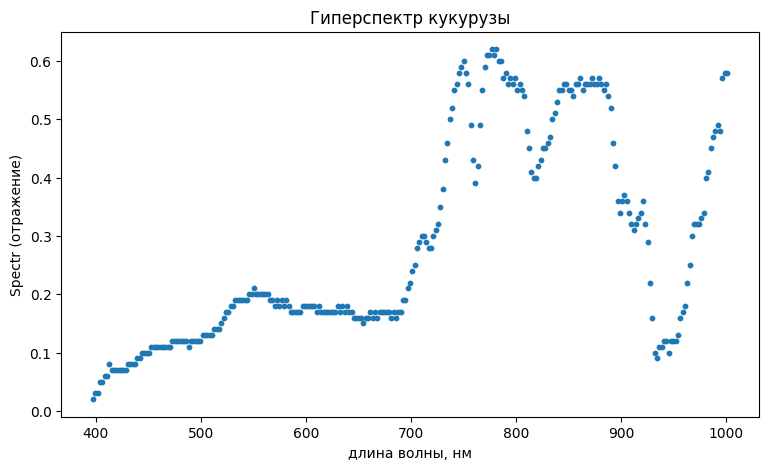

In [21]:
x_g = gipers['wavelength'].values      # длина волны, нм — факторный признак
Y_g = gipers['Spectr'].values          # коэффициент отражения — результативный признак
plt.figure(figsize=(9, 5))
plt.scatter(x_g, Y_g, s=10)
plt.xlabel('длина волны, нм'); plt.ylabel('Spectr (отражение)')
plt.title('Гиперспектр кукурузы'); plt.show()

Спектр отражения растительности имеет характерную форму: низкое отражение в видимой области (пигменты поглощают свет),
резкий рост в районе 680–750 нм («красный край») и плато в ближней ИК-области. Зависимость явно **нелинейная**,
поэтому от парной линейной модели стоит ожидать лишь грубой аппроксимации общего тренда.

### 1. Аналитическое решение (метод наименьших квадратов)

Модель линейной регрессии (аналитически): Y^ = -0.183428 + 0.00066816 * x


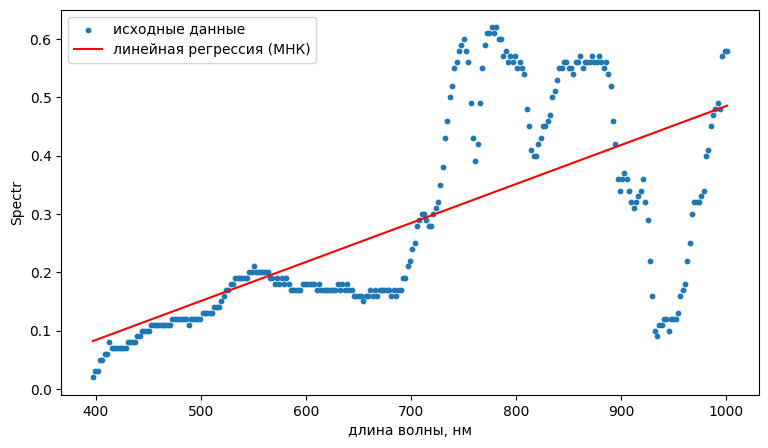

In [22]:
a1_an = ((x_g - x_g.mean()) * (Y_g - Y_g.mean())).mean() / ((x_g - x_g.mean()) ** 2).mean()
a0_an = Y_g.mean() - a1_an * x_g.mean()
print(f"Модель линейной регрессии (аналитически): Y^ = {a0_an:.6f} + {a1_an:.8f} * x")

x_space_g = np.linspace(x_g.min(), x_g.max(), 100)
plt.figure(figsize=(9, 5))
plt.scatter(x_g, Y_g, s=10, label='исходные данные')
plt.plot(x_space_g, a0_an + a1_an * x_space_g, 'r', label='линейная регрессия (МНК)')
plt.xlabel('длина волны, нм'); plt.ylabel('Spectr'); plt.legend(); plt.show()

### 2. Градиентный спуск

Используем класс `SimpleRegression` из примера. Значения x лежат в диапазоне ~400–1000, поэтому градиент по a1 в тысячи раз больше,
чем по a0: при «сыром» x приходится брать крошечный шаг α, и свободный член сходится крайне медленно.
Рассмотрим оба варианта: (а) градиентный спуск на исходном x и (б) на стандартизованном x с последующим пересчётом коэффициентов.

In [23]:
# (а) спуск на исходных данных: градиент в классе - сумма по объектам, поэтому alpha очень мал
regr_raw = SimpleRegression()
steps_raw, errors_raw = regr_raw.fit(x_g, Y_g, alpha=1e-9, epsylon=1e-6, max_steps=20000)
print(f"(а) исходный x:     Y^ = {regr_raw.a0:.6f} + {regr_raw.a1:.8f} * x,   MSE = {regr_raw.MSE(x_g, Y_g):.6f},  шагов: {len(steps_raw)}")

# (б) спуск на стандартизованном x: z = (x - mean) / std
x_mean, x_std = x_g.mean(), x_g.std()
z_g = (x_g - x_mean) / x_std
regr_std = SimpleRegression()
steps_std, errors_std = regr_std.fit(z_g, Y_g, alpha=0.001, epsylon=1e-6, max_steps=5000)
# обратный пересчёт: Y = b0 + b1*z = (b0 - b1*mean/std) + (b1/std)*x
a1_gd = regr_std.a1 / x_std
a0_gd = regr_std.a0 - regr_std.a1 * x_mean / x_std
print(f"(б) стандартиз. x:  Y^ = {a0_gd:.6f} + {a1_gd:.8f} * x,   MSE = {regr_std.MSE(z_g, Y_g):.6f},  шагов: {len(steps_std)}")
print(f"Аналитически:       Y^ = {a0_an:.6f} + {a1_an:.8f} * x")

(а) исходный x:     Y^ = -0.000117 + 0.00042144 * x,   MSE = 0.019664,  шагов: 20000
(б) стандартиз. x:  Y^ = -0.183428 + 0.00066816 * x,   MSE = 0.017684,  шагов: 5000
Аналитически:       Y^ = -0.183428 + 0.00066816 * x


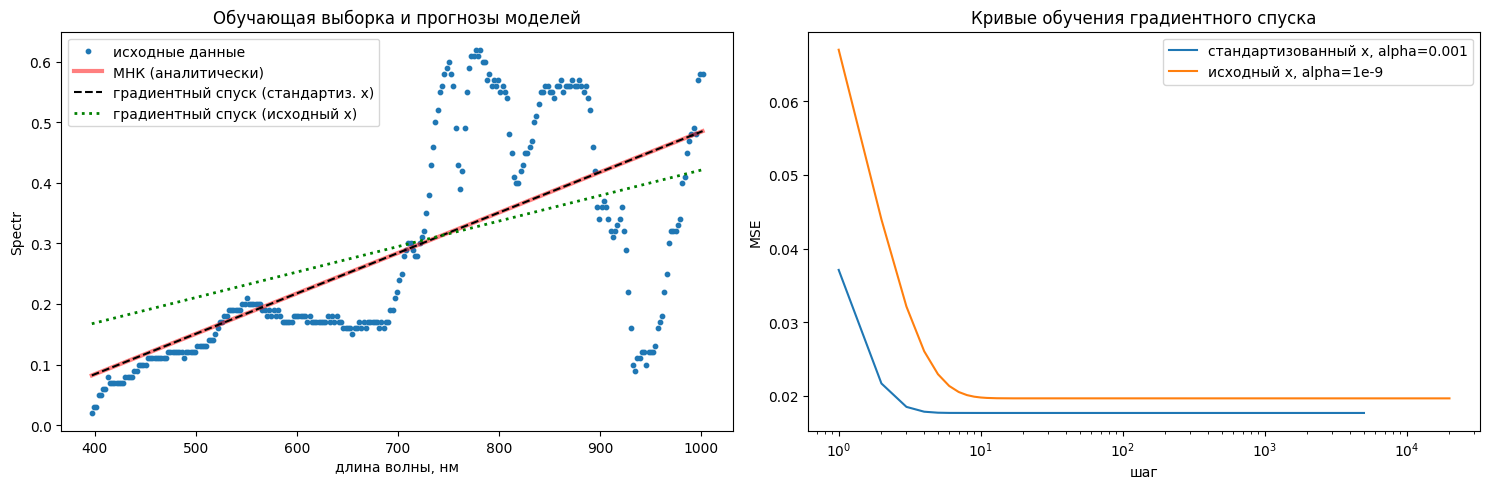

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(x_g, Y_g, s=10, label='исходные данные')
axes[0].plot(x_space_g, a0_an + a1_an * x_space_g, 'r', lw=3, alpha=0.5, label='МНК (аналитически)')
axes[0].plot(x_space_g, a0_gd + a1_gd * x_space_g, 'k--', label='градиентный спуск (стандартиз. x)')
axes[0].plot(x_space_g, regr_raw.predict(x_space_g), 'g:', lw=2, label='градиентный спуск (исходный x)')
axes[0].set_xlabel('длина волны, нм'); axes[0].set_ylabel('Spectr'); axes[0].legend()
axes[0].set_title('Обучающая выборка и прогнозы моделей')
axes[1].plot(steps_std, errors_std, label='стандартизованный x, alpha=0.001')
axes[1].plot(steps_raw, errors_raw, label='исходный x, alpha=1e-9')
axes[1].set_xscale('log'); axes[1].set_xlabel('шаг'); axes[1].set_ylabel('MSE')
axes[1].set_title('Кривые обучения градиентного спуска'); axes[1].legend()
plt.tight_layout(); plt.show()

alpha=0.008 — расходимость, MSE на последних шагах: [4.84938688e+12 5.50086515e+13 6.23986457e+14]


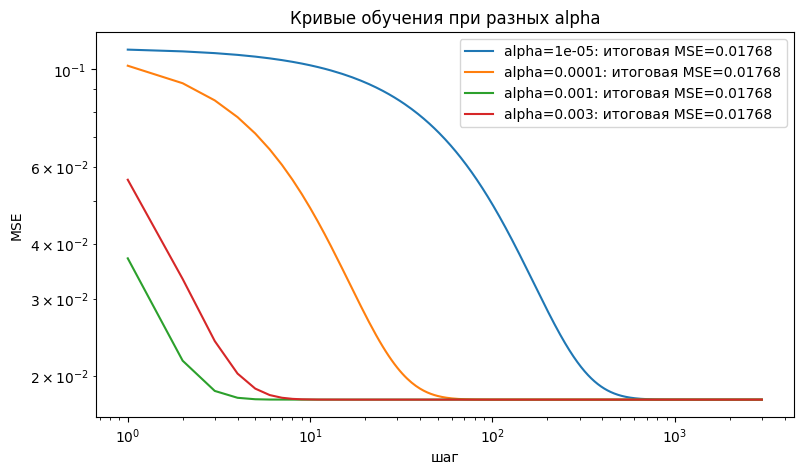

In [25]:
# Влияние скорости обучения (стандартизованный x)
plt.figure(figsize=(9, 5))
for alpha in [0.00001, 0.0001, 0.001, 0.003]:
    r = SimpleRegression()
    s, e = r.fit(z_g, Y_g, alpha=alpha, epsylon=1e-6, max_steps=3000)
    plt.plot(s, e, label=f'alpha={alpha}: итоговая MSE={e[-1]:.5f}')
r = SimpleRegression()
s, e = r.fit(z_g, Y_g, alpha=0.008, epsylon=1e-6, max_steps=15)
print('alpha=0.008 — расходимость, MSE на последних шагах:', np.round(e[-3:], 1))
plt.xscale('log'); plt.yscale('log'); plt.xlabel('шаг'); plt.ylabel('MSE'); plt.legend()
plt.title('Кривые обучения при разных alpha'); plt.show()

### 3. Оценка качества моделей

In [26]:
def metrics(y, y_hat):
    mse = ((y - y_hat) ** 2).mean()
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'MAE': np.abs(y - y_hat).mean(),
            'R2': 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()}

quality = pd.DataFrame({
    'МНК (аналитически)': metrics(Y_g, a0_an + a1_an * x_g),
    'ГС, стандартизованный x': metrics(Y_g, a0_gd + a1_gd * x_g),
    'ГС, исходный x': metrics(Y_g, regr_raw.predict(x_g)),
}).T.round(5)
quality

,MSE,RMSE,MAE,R2
МНК (аналитически),0.01768,0.13298,0.09683,0.43589
"ГС, стандартизованный x",0.01768,0.13298,0.09683,0.43589
"ГС, исходный x",0.01966,0.14023,0.11852,0.37274


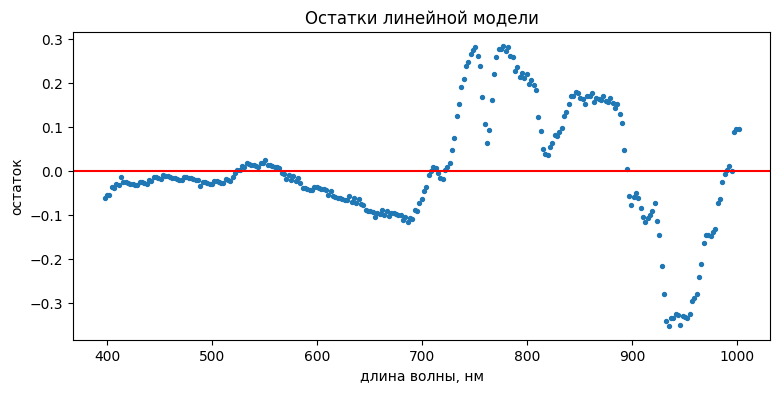

In [27]:
plt.figure(figsize=(9, 4))
plt.scatter(x_g, Y_g - (a0_an + a1_an * x_g), s=8)
plt.axhline(0, c='r'); plt.xlabel('длина волны, нм'); plt.ylabel('остаток')
plt.title('Остатки линейной модели'); plt.show()

Остатки имеют выраженную систематическую структуру (S-образную форму), а не случайный разброс вокруг нуля —
линейная модель не описывает форму спектра. Проверим, насколько лучше справится полиномиальная регрессия.

### Дополнительно: полиномиальная регрессия и регуляризация (Ridge, LASSO, Elastic Net)

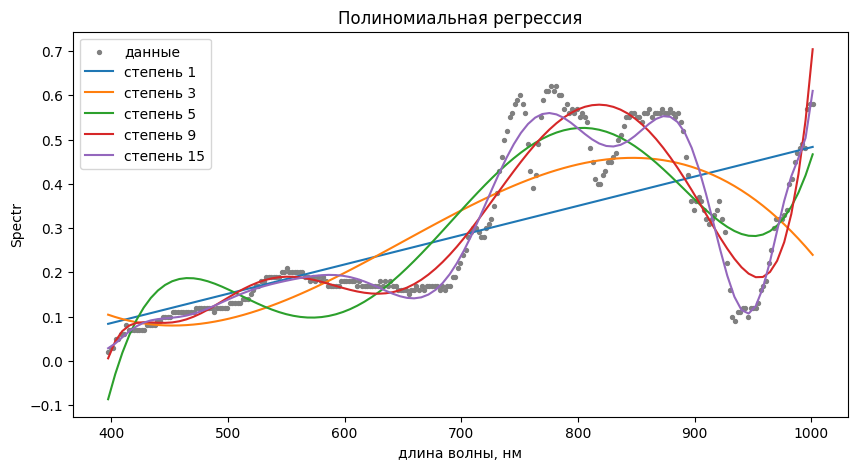

,модель,R2 train,R2 test
0,полином степени 1,0.4232,0.4658
1,полином степени 3,0.5920,0.6589
2,полином степени 5,0.7649,0.8119
3,полином степени 9,0.8809,0.9389
4,полином степени 15,0.9540,0.9682
5,полином 15 + Ridge(alpha=0.01),0.8854,0.9398
6,полином 15 + Lasso(alpha=0.0005),0.8557,0.9060
7,"полином 15 + ElasticNet(alpha=0.0005, l1_ratio...",0.8625,0.9140


In [28]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

Xg = x_g.reshape(-1, 1)
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, Y_g, test_size=0.3, random_state=42)

rows = []
plt.figure(figsize=(10, 5)); plt.scatter(x_g, Y_g, s=8, c='gray', label='данные')
for deg in [1, 3, 5, 9, 15]:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(deg), LinearRegression()).fit(Xg_tr, yg_tr)
    rows.append({'модель': f'полином степени {deg}', 'R2 train': m.score(Xg_tr, yg_tr), 'R2 test': m.score(Xg_te, yg_te)})
    plt.plot(x_space_g, m.predict(x_space_g.reshape(-1, 1)), label=f'степень {deg}')
for name, reg in [('Ridge(alpha=0.01)', Ridge(alpha=0.01)), ('Lasso(alpha=0.0005)', Lasso(alpha=0.0005, max_iter=100000)),
                  ('ElasticNet(alpha=0.0005, l1_ratio=0.5)', ElasticNet(alpha=0.0005, l1_ratio=0.5, max_iter=100000))]:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(15), StandardScaler(), reg).fit(Xg_tr, yg_tr)
    rows.append({'модель': f'полином 15 + {name}', 'R2 train': m.score(Xg_tr, yg_tr), 'R2 test': m.score(Xg_te, yg_te)})
plt.xlabel('длина волны, нм'); plt.ylabel('Spectr'); plt.legend(); plt.title('Полиномиальная регрессия'); plt.show()
pd.DataFrame(rows).round(4)

## Выводы по ПР 1-2

1. Аналитически (МНК) получена модель парной линейной регрессии отражения от длины волны; коэффициент при x положителен —
   с ростом длины волны отражение кукурузы в среднем растёт.
2. Градиентный спуск сходится к тем же коэффициентам, что и аналитическое решение, **только при стандартизации признака**:
   на исходном x (значения ~400–1000) допустимый шаг очень мал, и за 20 000 шагов свободный член практически не сдвигается от нуля,
   модель остаётся заметно хуже МНК. При слишком большом α (0.008 для стандартизованного x) спуск расходится.
3. Качество линейной модели низкое (R² ≈ 0.44, RMSE ≈ 0.13 при среднем отражении 0.28): прямая отражает лишь общий тренд роста,
   но не описывает форму спектра — низкое отражение в видимой области, резкий «красный край» около 700–750 нм, плато в ближнем ИК
   и провалы в полосах поглощения воды (~920–960 нм). Это видно по систематическим (неслучайным) остаткам.
4. Полиномиальная регрессия описывает спектр заметно лучше: R² на тестовой части растёт с 0.47 (степень 1) до 0.94 (степень 9)
   и 0.97 (степень 15). Регуляризация (Ridge, LASSO, Elastic Net) при выбранных α снижает R² до 0.91–0.94: на плотной выборке
   из 273 точек без шума переобучения практически нет, и штраф лишь упрощает модель (LASSO обнуляет часть коэффициентов).
   Регуляризация полезна там, где полином высокой степени начинает подстраиваться под шум и колебаться на краях диапазона.